# Skill Extraction Validation & Descriptive Analysis

This notebook builds on the cleaned and combined job-market dataset produced in the data collection phase.

Our goals are to:

- validate and refine the extracted technical skills, especially ambiguous terms such as **Go** and **R**
- measure overall skill demand across the full dataset
- compare skill demand across **data sources, seniority levels, and work models**
- identify common skill combinations
- compute normalized co-occurrence strength using **Jaccard similarity**
- prepare clean outputs for the later **salary-modeling** and **graph-analysis** phases

The main input for this notebook is:

- `Datasets/combined_data.csv`

At the end of the notebook, we export the following analysis files:

- `Datasets/skill_frequency_stats.csv` — overall skill frequency and demand percentage
- `Datasets/skill_by_source.csv` — skill demand by data source
- `Datasets/skill_by_seniority.csv` — skill demand by seniority level
- `Datasets/skill_by_workmode.csv` — skill demand by work model
- `Datasets/skill_pair_stats.csv` — skill co-occurrence counts and Jaccard similarity
- `Datasets/job_skills_clean.csv` — cleaned job-to-skill mapping for downstream analysis

These outputs will be used as inputs for the next phases of the project, particularly salary regression and skill-network analysis.

In [1]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [27]:
import pandas as pd
import numpy as np
import ast
import matplotlib.pyplot as plt
import re

from itertools import combinations
from collections import Counter

# Load Silvia's final combined dataset
df = pd.read_csv("/content/drive/MyDrive/final_combined_data_tech_only.csv")

print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

display(df.head())

# Inspect the core strcuture

print(df["source"].value_counts())
print(df["level"].value_counts())
print(df["work_mode"].value_counts())

print("\nMissing values:")
print(df.isna().sum().sort_values(ascending=False))

Dataset shape: (5939, 19)

Columns:
['Unnamed: 0', 'source', 'job_id', 'title', 'company', 'location', 'categories', 'level', 'pub_date', 'currency', 'annual_salary', 'description', 'url', 'work_mode', 'row_id', 'loose_key', 'job_uid', 'llm_is_tech_role', 'skills_clean']


,Unnamed: 0,source,job_id,title,company,location,categories,level,pub_date,currency,annual_salary,description,url,work_mode,row_id,loose_key,job_uid,llm_is_tech_role,skills_clean
0,0,muse,21666246.0,"Machine Learning Engineer, AI Inference Soluti...",General Motors,sunnyvale; ca,['data and analytics'],Entry,2026-10-07 21:51:43+00:00,USD,135050.0,Description General Motors is a global leader ...,https://www.themuse.com/jobs/generalmotors/mac...,Hybrid,0,general motors|machine learning engineer ai in...,0,True,"['airflow', 'c++', 'ci/cd', 'computer vision',..."
1,1,muse,16045945.0,Machine Learning Engineer - CV/NLP/Multimodal ...,TikTok,san jose; ca,['data and analytics'],Entry,2025-08-03 04:35:29+00:00,USD,152928.5,Responsibilities The algorithm team is respon...,https://www.themuse.com/jobs/tiktok/machine-le...,Onsite,1,tiktok|machine learning engineer cv nlp multim...,1,True,"['computer vision', 'llm / genai', 'nlp']"
2,3,muse,22030232.0,Machine Learning Engineer Graduate (Ads Signal...,TikTok,san jose; ca,['data and analytics'],Entry,2026-08-04 20:22:16+00:00,USD,192000.0,Responsibilities The Signal & Measurement tea...,https://www.themuse.com/jobs/tiktok/machine-le...,Onsite,3,tiktok|machine learning engineer graduate 2027...,3,True,"['apache spark', 'c++', 'go', 'java', 'llm / g..."
3,4,muse,19307581.0,Solutions Architect,Enterprise Mobility,st. louis; mo,['data and analytics'],Entry,2025-06-24 12:37:47+00:00,USD,149500.0,Overview The St. Louis Support Services Divisi...,https://www.themuse.com/jobs/enterprisemobilit...,Hybrid,4,enterprise mobility|solutions architect|Entry,4,True,"['aws', 'ci/cd', 'git', 'linux', 'mongodb', 'm..."
4,5,muse,21754340.0,"AI Engineer, Supercomputing, Special Programs ...",SpaceX,el segundo; ca; palo alto; ca; redmond; wa; wa...,['data and analytics'],Mid,2026-10-07 19:01:40+00:00,USD,182500.0,SpaceX was founded under the belief that a fut...,https://www.themuse.com/jobs/spacex/ai-enginee...,Onsite,5,spacex|ai engineer supercomputing special prog...,5,True,"['ci/cd', 'go', 'kubernetes', 'linux', 'python..."


source
himalayas    3294
muse         2645
Name: count, dtype: int64
level
Senior    3948
Mid       1595
Lead+      284
Entry      102
Intern      10
Name: count, dtype: int64
work_mode
Remote    3428
Onsite    2190
Hybrid     321
Name: count, dtype: int64

Missing values:
job_id              3294
url                 3294
location               4
currency               1
Unnamed: 0             0
source                 0
company                0
categories             0
level                  0
pub_date               0
title                  0
annual_salary          0
description            0
work_mode              0
row_id                 0
loose_key              0
job_uid                0
llm_is_tech_role       0
skills_clean           0
dtype: int64


In [28]:
# Parsing the Skills field

def parse_skills(value):
    if pd.isna(value):
        return []

    if isinstance(value, list):
        return value

    try:
        parsed = ast.literal_eval(value)

        if isinstance(parsed, list):
            return [
                str(skill).strip()
                for skill in parsed
                if str(skill).strip()
            ]

    except (ValueError, SyntaxError):
        pass

    return []

df["skills_list"] = df["skills_clean"].apply(parse_skills)
df["skill_count"] = df["skills_list"].apply(len)

df[["title", "skills_clean", "skills_list"]].head(10)

,title,skills_clean,skills_list
0,"Machine Learning Engineer, AI Inference Soluti...","['airflow', 'c++', 'ci/cd', 'computer vision',...","[airflow, c++, ci/cd, computer vision, git, li..."
1,Machine Learning Engineer - CV/NLP/Multimodal ...,"['computer vision', 'llm / genai', 'nlp']","[computer vision, llm / genai, nlp]"
2,Machine Learning Engineer Graduate (Ads Signal...,"['apache spark', 'c++', 'go', 'java', 'llm / g...","[apache spark, c++, go, java, llm / genai, nlp..."
3,Solutions Architect,"['aws', 'ci/cd', 'git', 'linux', 'mongodb', 'm...","[aws, ci/cd, git, linux, mongodb, mysql, postg..."
4,"AI Engineer, Supercomputing, Special Programs ...","['ci/cd', 'go', 'kubernetes', 'linux', 'python...","[ci/cd, go, kubernetes, linux, python, terraform]"
5,Gateway Fleet Specialist,['sql'],[sql]
6,Non-Agency RMBS & CLO Research Analyst/Associate,"['python', 'sql']","[python, sql]"
7,2026 University Hire (U.S.) - Information & Di...,"['apache spark', 'azure', 'databricks', 'keras...","[apache spark, azure, databricks, keras, power..."
8,"Technical Operations Engineer, Customer Succes...","['python', 'r', 'sql']","[python, r, sql]"
9,"Operations Engineer, Applied AI (Application S...","['git', 'linux', 'llm / genai', 'python']","[git, linux, llm / genai, python]"


In [29]:
# Document the analytical sample

total_jobs = len(df)
jobs_with_skills = (df["skill_count"] > 0).sum()

print("Total jobs:", total_jobs)
print("Jobs with at least one skill:", jobs_with_skills)
print("Coverage:", jobs_with_skills / total_jobs * 100)

Total jobs: 5939
Jobs with at least one skill: 5939
Coverage: 100.0


##### The final combined dataset was already filtered upstream to retain jobs with detected technical skills. Therefore, 100% coverage refers to the analytical sample, not to perfect extraction accuracy.

#### <b>Recompute final overall skill demand</b>

In [33]:
skills_exploded = (
    df[["job_uid", "skills_list"]]
    .explode("skills_list")
    .dropna()
    .rename(columns={"skills_list": "skill"})
)

In [34]:
# Frequency

skill_frequency = (
    skills_exploded
    .groupby("skill")
    .agg(job_count=("job_uid", "nunique"))
    .reset_index()
)

skill_frequency["demand_pct"] = (
    skill_frequency["job_count"]
    / df["job_uid"].nunique()
    * 100
)

skill_frequency = (
    skill_frequency
    .sort_values("job_count", ascending=False)
    .reset_index(drop=True)
)

display(skill_frequency.head(20))

,skill,job_count,demand_pct
0,python,3833,64.539485
1,sql,2707,45.580064
2,git,2231,37.565247
3,aws,2041,34.366055
4,ci/cd,2034,34.248190
5,llm / genai,2034,34.248190
6,azure,1754,29.533592
7,gcp,1611,27.125779
8,linux,1600,26.940562
9,nlp,1405,23.657181


#### <b>Plot Top Skills</b>

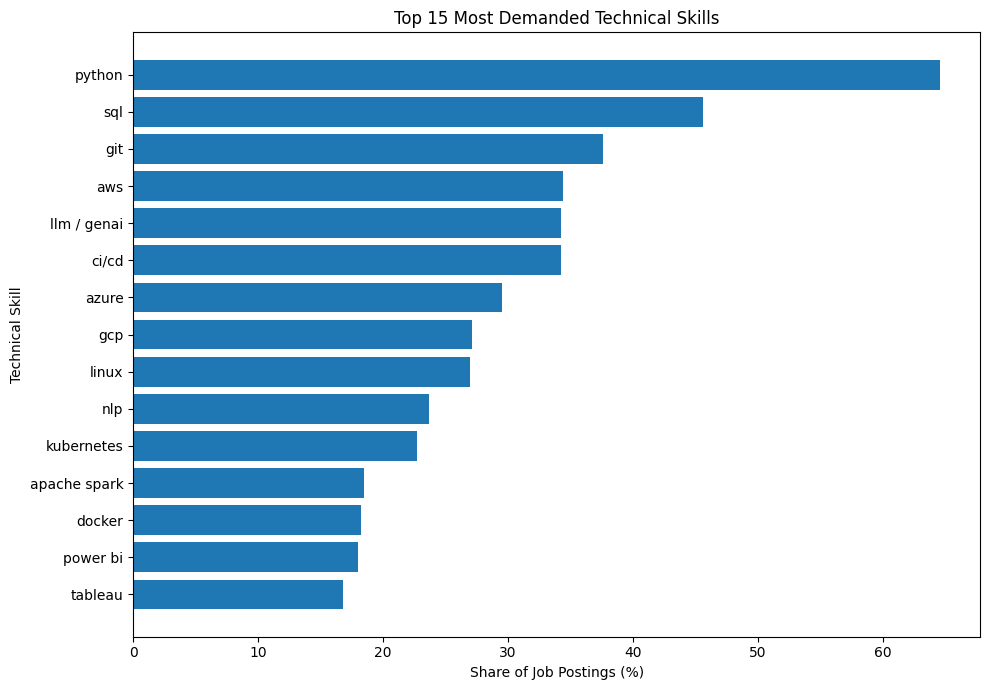

In [35]:
top_skills = (
    skill_frequency
    .head(15)
    .sort_values("demand_pct")
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_skills["skill"],
    top_skills["demand_pct"]
)

plt.xlabel("Share of Job Postings (%)")
plt.ylabel("Technical Skill")
plt.title("Top 15 Most Demanded Technical Skills")

plt.tight_layout()
plt.show()

#### <b>Compare skill demand by source</b>

In [36]:
# Because Muse and Himalayas have different patterns, we need to compare them separately
skill_source = (
    skills_exploded
    .merge(
        df[["job_uid", "source"]],
        on="job_uid",
        how="left"
    )
)

In [37]:
jobs_per_source = (
    df.groupby("source")["job_uid"]
    .nunique()
    .rename("total_jobs")
)

skill_by_source = (
    skill_source
    .groupby(["source", "skill"])
    .agg(job_count=("job_uid", "nunique"))
    .reset_index()
    .merge(jobs_per_source, on="source")
)

skill_by_source["demand_pct"] = (
    skill_by_source["job_count"]
    / skill_by_source["total_jobs"]
    * 100
)

In [38]:
# Top 10 per source

top_by_source = (
    skill_by_source
    .sort_values(
        ["source", "demand_pct"],
        ascending=[True, False]
    )
    .groupby("source")
    .head(10)
)

display(top_by_source)

,source,skill,job_count,total_jobs,demand_pct
32,himalayas,python,2150,3294,65.270188
41,himalayas,sql,1676,3294,50.880389
2,himalayas,aws,1403,3294,42.592593
13,himalayas,git,1324,3294,40.194293
23,himalayas,llm / genai,1244,3294,37.765634
8,himalayas,ci/cd,1218,3294,36.976321
3,himalayas,azure,1047,3294,31.785064
12,himalayas,gcp,921,3294,27.959927
22,himalayas,linux,817,3294,24.802672
20,himalayas,kubernetes,801,3294,24.316940


#### <b>Analyze Demand by Seniority</b>

In [39]:
# Merge skills with the same metadata

skill_jobs = skills_exploded.merge(
    df[
        [
            "job_uid",
            "source",
            "level",
            "work_mode",
            "annual_salary"
        ]
    ],
    on="job_uid",
    how="left"
)

In [40]:
# Calculate skill demand within each level

jobs_per_level = (
    df.groupby("level")["job_uid"]
    .nunique()
    .rename("total_jobs")
)

skill_by_level = (
    skill_jobs
    .groupby(["level", "skill"])
    .agg(job_count=("job_uid", "nunique"))
    .reset_index()
    .merge(jobs_per_level, on="level")
)

skill_by_level["demand_pct"] = (
    skill_by_level["job_count"]
    / skill_by_level["total_jobs"]
    * 100
)

In [41]:
# Excluse intern from comparison because it contains very few jobs

skill_by_level_filtered = skill_by_level[
    skill_by_level["level"] != "Intern"
]

#### <b>Analyze demand by work mode</b>

In [42]:
jobs_per_mode = (
    df.groupby("work_mode")["job_uid"]
    .nunique()
    .rename("total_jobs")
)

skill_by_workmode = (
    skill_jobs
    .groupby(["work_mode", "skill"])
    .agg(job_count=("job_uid", "nunique"))
    .reset_index()
    .merge(jobs_per_mode, on="work_mode")
)

skill_by_workmode["demand_pct"] = (
    skill_by_workmode["job_count"]
    / skill_by_workmode["total_jobs"]
    * 100
)

Himalayas is a remote-only source, so work mode and data source are partially confounded. Work-mode comparisons should therefore be interpreted cautiously and checked against source-specific results.

#### <b>Build skill-pair statistics</b>

In [54]:
skills_by_job = (
    df.set_index("job_uid")["skills_list"]
)

In [55]:
# Count combination

pair_counter = Counter()

for skills in skills_by_job:
    for pair in combinations(sorted(set(skills)), 2):
        pair_counter[pair] += 1

In [57]:
# DF conversion

skill_pairs = pd.DataFrame(
    [
        {
            "skill_1": pair[0],
            "skill_2": pair[1],
            "job_count": count
        }
        for pair, count in pair_counter.items()
    ]
)

skill_pairs = skill_pairs.sort_values(
    "job_count",
    ascending=False
)

#### <b>Add Jaccard similarity to normalize very common skills</b>

In [58]:
skill_counts = dict(
    skills_exploded
    .groupby("skill")["job_uid"]
    .nunique()
)

In [59]:
def compute_jaccard(row):
    a = skill_counts[row["skill_1"]]
    b = skill_counts[row["skill_2"]]
    intersection = row["job_count"]

    union = a + b - intersection

    return intersection / union

In [60]:
# Apply:

skill_pairs["jaccard"] = (
    skill_pairs.apply(
        compute_jaccard,
        axis=1
    )
)

display(
    skill_pairs
    .sort_values("job_count", ascending=False)
    .head(20)
)


,skill_1,skill_2,job_count,jaccard
124,python,sql,1966,0.429821
18,ci/cd,git,1692,0.657598
40,llm / genai,python,1575,0.366962
33,git,python,1549,0.343079
160,aws,python,1507,0.345088
22,ci/cd,python,1454,0.329481
180,aws,azure,1390,0.577963
196,azure,gcp,1360,0.678304
72,aws,git,1330,0.452073
183,aws,gcp,1290,0.546147


### Skill Co-occurrence Patterns

The table above shows the most common pairs of technical skills found within the same job postings.

- **Python and SQL** form the most frequent pair, appearing together in 1,649 postings, suggesting that they are a foundational combination across many data and technical roles.
- Cloud technologies also show strong relationships. For example, **AWS–Azure** and **Azure–GCP** have relatively high Jaccard similarity scores, indicating that cloud platforms are often requested together rather than in isolation.
- **Python–LLM/GenAI** and **Python–Apache Spark** are also common combinations, reflecting the importance of Python across AI, machine learning, and data engineering roles.
- The Jaccard score helps distinguish genuinely strong relationships from pairs that simply involve very common skills. A higher value means that the two skills tend to occur together more consistently.

These co-occurrence relationships will later be used to build the skill network for the graph-analysis phase.
**Interpretation note:** `job_count` measures raw co-occurrence frequency, while `jaccard` measures normalized similarity. Therefore, a pair can have a high job count but only a moderate Jaccard score if both skills are individually very common.

In [61]:
# Also, inspect strongest normalized pairs:

display(
    skill_pairs[
        skill_pairs["job_count"] >= 20
    ]
    .sort_values("jaccard", ascending=False)
    .head(20)
)

,skill_1,skill_2,job_count,jaccard
165,numpy,pandas,579,0.861607
101,mongodb,redis,556,0.767956
240,docker,kubernetes,1003,0.701399
105,mysql,redis,496,0.688889
196,azure,gcp,1360,0.678304
98,mongodb,mysql,513,0.677675
18,ci/cd,git,1692,0.657598
606,redis,redshift,478,0.656593
70,pytorch,tensorflow,533,0.642943
441,bigquery,redshift,537,0.634002


#### <b>Exports</b>

In [62]:
skill_frequency.to_csv(
    "skill_frequency_stats.csv",
    index=False
)

skill_by_source.to_csv(
    "skill_by_source.csv",
    index=False
)

skill_by_level.to_csv(
    "skill_by_seniority.csv",
    index=False
)

skill_by_workmode.to_csv(
    "skill_by_workmode.csv",
    index=False
)

skill_pairs.to_csv(
    "skill_pair_stats.csv",
    index=False
)

In [65]:
# Export clean-job table

job_skills_clean = (
    df[["job_uid", "skills_list"]]
    .explode("skills_list")
    .dropna()
    .rename(columns={"skills_list": "skill"})
)

job_skills_clean.to_csv(
    "job_skills_clean.csv",
    index=False
)